<h1 align="center">
<h1 align="center"> Tarea 3 - Web Usage Mining
<h2 align="center">  Integrantes: Fernando Cáceres y Cristóbal Gajardo.
<h3 align="center"> IN5529 - Inteligencia Artificial Aplicada a la Web
<h3 align="center"> Primavera 2025

---

# Introducción

En esta tarea aplicamos técnicas de Web Usage Mining para analizar el comportamiento de los usuarios de un sitio de e-commerce y, a partir de ello, construir sistemas de recomendación sobre datos de reseñas de productos de Amazon. La tarea se divide en dos partes.

En la **Parte 1**, trabajamos con el dataset EClog. Primero realizamos la selección de variables relevantes y una limpieza de los registros del log (remoción de recursos estáticos, códigos de error y bots). Luego transformamos las marcas de tiempo y reconstruimos sesiones de navegación utilizando dos heurísticas: una basada sólo en tiempo de inactividad de 30 minutos y otra que además considera cambios de IP y UserAgent. Finalmente, hacemos un análisis exploratorio de las sesiones obtenidas para identificar patrones de navegación (duraciones, cantidad de hits, distribución horaria, sistemas operativos, etc.).

En la **Parte 2**, construimos e implementamos distintos sistemas de recomendación usando reseñas de las categorías **Digital Music** y **Health and Personal Care**. Implementamos desde cero dos variantes de filtrado colaborativo (basado en usuarios y basado en ítems) y un modelo baseline adicional basado en el promedio global de rating. Luego comparamos el desempeño de estos métodos mediante la métrica RMSE.




##Librerias


In [11]:
# Librerias
!pip install numpy==1.26.4

In [12]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

from scipy.sparse import csr_matrix
from collections import defaultdict

# Reconstrucción de Sesiones

In [ ]:
# Subiendo y leyendo datos
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
ruta = '/content/drive/My Drive/eclog.csv'
df = pd.read_csv(ruta)
df.head()


## Selección

A partir del log original EClog se seleccionan sólo las columnas necesarias para reconstruir usuarios y sesiones: identificadores de usuario (`UserId`), IP (`IpId`), método HTTP, URI solicitada, código de respuesta (`ResponseCode`), agente de usuario (`UserAgent`) y la marca de tiempo (`TimeStamp`). Esta reducción evita cargar información irrelevante para el análisis de navegación y simplifica el preprocesamiento posterior, manteniendo sólo aquello que realmente se utiliza para definir usuarios, filtrar tráfico no humano y ordenar eventos en el tiempo.


In [13]:
# Selección
cols_keep = [
    'UserId', 'IpId',
    'HttpMethod', 'Uri', 'ResponseCode', 'UserAgent',
    'TimeStamp'
]

# Sólo copia
df = df[[c for c in cols_keep if c in df.columns]].copy()

print(df.shape)
df.head()

(5859615, 7)


,UserId,IpId,HttpMethod,Uri,ResponseCode,UserAgent,TimeStamp
0,-,1PL,GET,/p-9710.html,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000
1,-,1PL,GET,/szablony/shop_11.rwd/css/style.php?ncss=style...,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000
2,-,1PL,GET,/javascript/skrypty.php,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000
3,-,1PL,GET,/javascript/produkt.php,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000
4,-,1PL,GET,/szablony/shop_11.rwd/obrazki/szablon/info.png,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516010000000


In [14]:
# Limpieza
def string_remover(df_in, column, string_list):
    df_out = df_in.copy()
    for s in string_list:
        df_out = df_out.drop(
            df_out[df_out[column].str.lower().str.contains(s, na=True)].index
        )
    return df_out

# Quitando recursos estáticos/multimedia
df_clean = string_remover(df, 'Uri', [
    '.png','.jpeg','.ico','.gif','.jpg','.tif','.bmp',
    '.mp3','.css','.js','.swf','.cgi','/image/','/settings/','/static/'
])

# Manteniendo solo métodos útiles
df_clean = df_clean[df_clean['HttpMethod'].isin(['GET', 'POST'])]

# Manteniendo solo respuestas válidas: 2xx–3xx
df_clean = df_clean[
    df_clean['ResponseCode'].astype(str).str.match(r'^[23]\d{2}$', na=False)
]

# Eliminando bots/crawlers por 'UserAgent'
df_clean = string_remover(df_clean, 'UserAgent', [
    'crawl','spider','krawl','bot','wget','curl','python-requests'
])

# Reset de índices y vista rápida
df_clean = df_clean.reset_index(drop=True)
df_clean.head()


,UserId,IpId,HttpMethod,Uri,ResponseCode,UserAgent,TimeStamp
0,-,1PL,GET,/p-9710.html,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000
1,-,1PL,GET,/javascript/skrypty.php,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000
2,-,1PL,GET,/javascript/produkt.php,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000
3,-,2PL,POST,/inne/informacja_online.php,200,Mozilla/5.0 (Windows NT 6.1; Win64; x64; rv:70...,637107516010000000
4,-,3PL,POST,/inne/informacja_online.php,200,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,637107516020000000


## Preprocesamiento y transformación

Primero se limpia el log eliminando requests a recursos estáticos o multimedia (imágenes, íconos, CSS, JS, etc.), ya que no aportan a entender el flujo de navegación lógico del usuario. Luego se filtran sólo códigos HTTP exitosos (rango 2xx–3xx) y se remueven agentes de usuario que corresponden a crawlers o bots (patrones como `crawl`, `bot`, `wget`, `curl`, etc.).

Después, la columna `TimeStamp`, que está en ticks de 100 nanosegundos desde el epoch de .NET, se transforma a segundos Unix y luego a un `datetime` en UTC. A partir de esta fecha se generan columnas de apoyo (`UTC_DATETIME`, `DATE`, `TIME`) que permiten ordenar correctamente los eventos y hacer análisis por día y hora. El resultado es un log depurado, ordenado temporalmente y con variables de tiempo interpretables.


In [15]:
# Transformando variables de tiempo
UNIX_EPOCH_TICKS = 621355968000000000  # ticks

# Convirtiendo TimeStamp (ticks de 100 ns) → segundos Unix
ticks = pd.to_numeric(df_clean['TimeStamp'], errors='coerce')
unix_ticks = ticks - UNIX_EPOCH_TICKS
unix_seconds = unix_ticks / 10_000_000.0  # 10 m.t por seg

# Datetime en UTC
dt = pd.to_datetime(unix_seconds, unit='s', utc=True, errors='coerce')
df_clean['UTC_DATETIME'] = dt.dt.tz_convert('UTC')

# Date y Time
df_clean['DATE'] = df_clean['UTC_DATETIME'].dt.strftime('%d/%b/%Y')
df_clean['TIME'] = df_clean['UTC_DATETIME'].dt.strftime('%H:%M:%S')

# Reordenando
cols_show = ['UserId','IpId','HttpMethod','Uri','ResponseCode','UserAgent',
             'TimeStamp','UTC_DATETIME','DATE','TIME']
cols_show = [c for c in cols_show if c in df_clean.columns]
df_clean[cols_show].head()


,UserId,IpId,HttpMethod,Uri,ResponseCode,UserAgent,TimeStamp,UTC_DATETIME,DATE,TIME
0,-,1PL,GET,/p-9710.html,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000,2019-11-30 23:00:00+00:00,30/Nov/2019,23:00:00
1,-,1PL,GET,/javascript/skrypty.php,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000,2019-11-30 23:00:00+00:00,30/Nov/2019,23:00:00
2,-,1PL,GET,/javascript/produkt.php,200,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,637107516000000000,2019-11-30 23:00:00+00:00,30/Nov/2019,23:00:00
3,-,2PL,POST,/inne/informacja_online.php,200,Mozilla/5.0 (Windows NT 6.1; Win64; x64; rv:70...,637107516010000000,2019-11-30 23:00:01+00:00,30/Nov/2019,23:00:01
4,-,3PL,POST,/inne/informacja_online.php,200,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,637107516020000000,2019-11-30 23:00:02+00:00,30/Nov/2019,23:00:02


## Reconstrucción de sesiones

Para identificar usuarios se crea una columna `USER`. Cuando el `UserId` está disponible y es válido, se usa directamente; en caso contrario, se construye un identificador combinando `IpId` y `UserAgent`. Esto permite agrupar las peticiones de un mismo navegador/dispositivo incluso cuando no hay un identificador explícito de usuario.

Con los registros ordenados por `USER` y `UTC_DATETIME` se aplican dos heurísticas de reconstrucción de sesiones:

- **Heurística H1 (`SESSION_30`)**: se recorre la secuencia de hits de cada usuario y se inicia una nueva sesión si el tiempo desde el último hit supera los 30 minutos. La duración máxima de una sesión queda limitada a este umbral, y cada grupo continuo de actividad se etiqueta con un identificador de sesión.
- **Heurística H2 (`SESSION_H2`)**: parte de la misma regla de inactividad de 30 minutos, pero añade una condición adicional: si cambia la IP o el `UserAgent` entre dos hits consecutivos, también se corta la sesión y se inicia una nueva. Esta segunda heurística es más estricta respecto a cambios de dispositivo o navegador.

Sobre estas etiquetas de sesión se calcula un resumen por sesión: hora de inicio y término, duración en segundos, número de hits, URI de entrada (landing) y URI de salida (exit). Esto permite comparar directamente el efecto de cada heurística en la cantidad y características de las sesiones resultantes.


In [16]:
# Reconocimiento de usuarios

# Columna USER para identificar al usuario
df_clean['USER'] = np.where(
    df_clean['UserId'].notna() & (df_clean['UserId'].astype(str) != '-'),
    df_clean['UserId'].astype(str),
    (df_clean['IpId'].fillna('') + '|' + df_clean['UserAgent'].fillna('')).astype(str)
)

# Orden temporal por usuario (como en el auxiliar)
df_clean = df_clean.sort_values(['USER','UTC_DATETIME']).reset_index(drop=True)
df_clean[['USER','UTC_DATETIME','Uri']].head()


,USER,UTC_DATETIME,Uri
0,10000PL|Mozilla/5.0 (iPhone; CPU iPhone OS 12_...,2019-12-03 11:24:52+00:00,/p-4964.html?gclid=EAIaIQobChMI0ubymNmX5gIV1eW...
1,10000PL|Mozilla/5.0 (iPhone; CPU iPhone OS 12_...,2019-12-03 11:24:53+00:00,/javascript/skrypty.php
2,10000PL|Mozilla/5.0 (iPhone; CPU iPhone OS 12_...,2019-12-03 11:24:53+00:00,/javascript/produkt.php
3,10000PL|Mozilla/5.0 (iPhone; CPU iPhone OS 12_...,2019-12-03 11:24:58+00:00,/inne/informacja_online.php
4,10000PL|Mozilla/5.0 (iPhone; CPU iPhone OS 12_...,2019-12-03 11:26:52+00:00,/inne/informacja_online.php


In [17]:
key = np.where(
    df_clean['UserId'].notna() & (df_clean['UserId'] != '-'),
    df_clean['UserId'].astype(str),
    (df_clean['IpId'].fillna('') + '|' + df_clean['UserAgent'].fillna('')).astype(str)
)
df_clean['USER'] = pd.factorize(key)[0] + 1
df_clean.head()


,UserId,IpId,HttpMethod,Uri,ResponseCode,UserAgent,TimeStamp,UTC_DATETIME,DATE,TIME,USER
0,-,10000PL,GET,/p-4964.html?gclid=EAIaIQobChMI0ubymNmX5gIV1eW...,200,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,637109690920000000,2019-12-03 11:24:52+00:00,03/Dec/2019,11:24:52,1
1,-,10000PL,GET,/javascript/skrypty.php,200,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,637109690930000000,2019-12-03 11:24:53+00:00,03/Dec/2019,11:24:53,1
2,-,10000PL,GET,/javascript/produkt.php,200,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,637109690930000000,2019-12-03 11:24:53+00:00,03/Dec/2019,11:24:53,1
3,-,10000PL,POST,/inne/informacja_online.php,200,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,637109690980000000,2019-12-03 11:24:58+00:00,03/Dec/2019,11:24:58,1
4,-,10000PL,POST,/inne/informacja_online.php,200,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,637109692120000000,2019-12-03 11:26:52+00:00,03/Dec/2019,11:26:52,1


In [18]:
# Heurísticas
from datetime import timedelta

# Orden temporal por usuario
df_clean = df_clean.sort_values(['USER','UTC_DATETIME']).reset_index(drop=True)

SESSION_TIMEOUT = 30 * 60  # 30 min en seg
df_clean['SESSION_30'] = -1

for u, g in df_clean.groupby('USER', sort=False):
    s_id = 0
    last_t = None
    s_start = None

    for idx, t in zip(g.index, g['UTC_DATETIME']):
        new_session = (
            (last_t is None) or
            ((t - last_t).total_seconds() > SESSION_TIMEOUT) or                    # inactividad >= 30m
            (s_start is not None and (t - s_start).total_seconds() > SESSION_TIMEOUT)  # cap 30m por sesión
        )
        if new_session:
            s_id += 1
            s_start = t
        df_clean.loc[idx, 'SESSION_30'] = s_id
        last_t = t

ses_30 = (df_clean
          .groupby(['USER','SESSION_30'])
          .agg(start=('UTC_DATETIME','min'),
               end=('UTC_DATETIME','max'),
               hits=('Uri','count'))
          .reset_index())
ses_30['duration_sec'] = (ses_30['end'] - ses_30['start']).dt.total_seconds()
ses_30.head()


,USER,SESSION_30,start,end,hits,duration_sec
0,1,1,2019-12-03 11:24:52+00:00,2019-12-03 11:27:57+00:00,6,185.0
1,2,1,2019-12-03 11:25:12+00:00,2019-12-03 11:25:19+00:00,4,7.0
2,3,1,2019-12-03 11:25:39+00:00,2019-12-03 11:25:45+00:00,4,6.0
3,4,1,2019-12-03 11:26:19+00:00,2019-12-03 11:34:55+00:00,25,516.0
4,5,1,2019-12-03 11:26:54+00:00,2019-12-03 11:27:00+00:00,4,6.0


In [19]:
# Asegurar orden temporal por usuario
df_clean = df_clean.sort_values(['USER', 'UTC_DATETIME']).reset_index(drop=True)

SESSION_TIMEOUT_H2 = 30 * 60  # 30 minutos (segundos)
df_clean['SESSION_H2'] = -1

for u, g in df_clean.groupby('USER', sort=False):
    s_id = 0
    last_t = None
    last_ip = None
    last_ua = None

    for idx, (t, ip, ua) in zip(g.index, g[['UTC_DATETIME','IpId','UserAgent']].itertuples(index=False, name=None)):
        # Regla 1: inactividad >= 30m
        new_by_time = (last_t is None) or ((t - last_t).total_seconds() > SESSION_TIMEOUT_H2)
        # Regla 2: cambio de IP o de UserAgent (cambio de dispositivo =>nueva sesion)
        new_by_device = (last_ip is not None and ip != last_ip) or (last_ua is not None and ua != last_ua)

        # Cortar sesión si se cumple cualquiera
        if new_by_time or new_by_device:
            s_id += 1

        df_clean.loc[idx, 'SESSION_H2'] = s_id
        last_t, last_ip, last_ua = t, ip, ua


## Descubrimiento de patrones

Con las sesiones reconstruidas se realiza un análisis exploratorio. Para ambas heurísticas se calcula la distribución de duración y número de hits por sesión, además de métricas agregadas como el bounce rate (proporción de sesiones de un solo hit) y el número de sesiones por usuario. En general, se observan muchas sesiones muy cortas (medianas de pocos segundos y con 1–2 hits), y una cola larga de sesiones más extensas. La heurística H2, al ser más estricta, genera menos sesiones totales pero tiende a fragmentar aquellas que presentan cambios de IP o dispositivo.

Se construye también un resumen de landings y exits, donde se identifican las páginas más frecuentes como punto de entrada y de salida del sitio, lo que da señales sobre páginas típicas de acceso (por ejemplo, páginas de producto o categorías) y posibles puntos de fuga de usuarios.

Adicionalmente, se extrae una variable de sistema operativo (`OS`) a partir del `UserAgent`, se asigna el OS del primer hit a cada sesión y se analiza la distribución de sesiones por sistema operativo. En el gráfico correspondiente se observa que un conjunto acotado de sistemas (por ejemplo, Windows, Android, iOS) concentra la mayoría de los inicios de sesión, lo que confirma una fuerte dependencia en unos pocos tipos de dispositivo.

Finalmente, se grafica la distribución horaria de inicio de sesiones para ambas heurísticas y se comparan sus duraciones mediante un boxplot. Estos gráficos muestran en qué franjas horarias el sitio concentra más actividad y cómo H1 y H2 afectan la cantidad y longitud de las sesiones. En resumen, las sesiones tienden a ser muy cortas, con alta tasa de rebotes y fuerte concentración en pocos sistemas operativos y horarios específicos.


In [20]:
# Sistemas operativos
import re

def extract_os(user_agent):
    user_agent = str(user_agent).lower()
    if 'windows' in user_agent:
        return 'Windows'
    elif 'macintosh' in user_agent or 'mac os x' in user_agent:
        return 'macOS'
    elif 'android' in user_agent:
        return 'Android'
    elif 'iphone' in user_agent or 'ipad' in user_agent or 'ipod' in user_agent:
        return 'iOS'
    elif 'linux' in user_agent:
        # Check for more specific Linux distributions if needed, e.g., Ubuntu
        return 'Linux'
    elif 'chromeos' in user_agent:
        return 'Chrome OS'
    elif 'blackberry' in user_agent:
        return 'BlackBerry OS'
    elif 'firefox' in user_agent and 'mobile' in user_agent:
        return 'Firefox OS'
    return 'Other'

df_clean['OS'] = df_clean['UserAgent'].apply(extract_os)

# Display the first few rows with the new OS column
df_clean[['USER', 'UTC_DATETIME', 'UserAgent', 'OS', 'SESSION_H2']].head()

,USER,UTC_DATETIME,UserAgent,OS,SESSION_H2
0,1,2019-12-03 11:24:52+00:00,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,macOS,1
1,1,2019-12-03 11:24:53+00:00,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,macOS,1
2,1,2019-12-03 11:24:53+00:00,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,macOS,1
3,1,2019-12-03 11:24:58+00:00,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,macOS,1
4,1,2019-12-03 11:26:52+00:00,Mozilla/5.0 (iPhone; CPU iPhone OS 12_4_3 like...,macOS,1


In [21]:
# Para cada sesión, tomamos el OS del primer hit
session_os_info = df_clean.sort_values(['USER', 'SESSION_H2', 'UTC_DATETIME'])
session_os_info = session_os_info.groupby(['USER', 'SESSION_H2'])['OS'].first().reset_index()

# Contar la distribución de los sistemas operativos por sesión
os_distribution = session_os_info['OS'].value_counts().reset_index()
os_distribution.columns = ['OS', 'Session_Count']

display(os_distribution)

,OS,Session_Count
0,Android,47578
1,Windows,15801
2,macOS,5222
3,Other,2718
4,Linux,817


/tmp/ipython-input-3438187712.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='OS', y='Session_Count', data=os_distribution, palette='viridis')


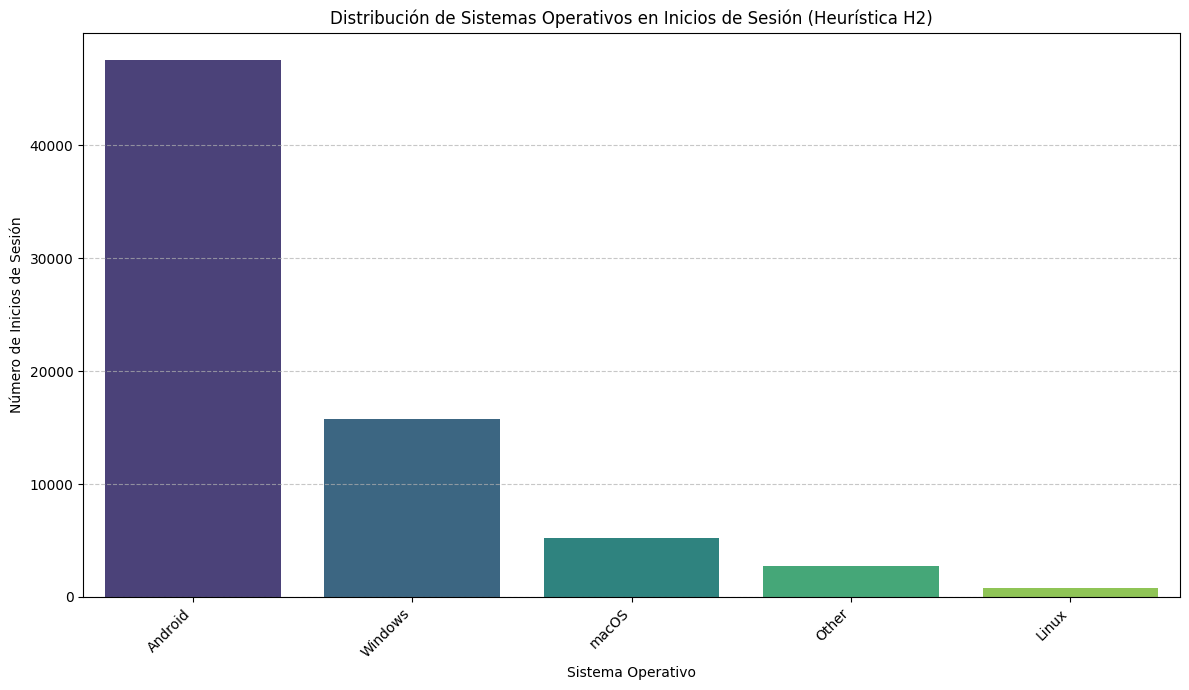

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.barplot(x='OS', y='Session_Count', data=os_distribution, palette='viridis')
plt.title('Distribución de Sistemas Operativos en Inicios de Sesión (Heurística H2)')
plt.xlabel('Sistema Operativo')
plt.ylabel('Número de Inicios de Sesión')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [23]:
# Resumen por sesión
def summarize_sessions(df, session_col):
    ses = (df
           .groupby(['USER', session_col], as_index=False)
           .agg(start=('UTC_DATETIME','min'),
                end=('UTC_DATETIME','max'),
                hits=('Uri','count')))
    ses['duration_sec'] = (ses['end'] - ses['start']).dt.total_seconds()
    # landing/exit (primer y último URI de la sesión)
    first_last = (df.sort_values(['USER', session_col, 'UTC_DATETIME'])
                    .groupby(['USER', session_col])['Uri']
                    .agg(landing='first', exit='last')
                    .reset_index())
    ses = ses.merge(first_last, on=['USER', session_col], how='left')
    return ses

ses_30 = summarize_sessions(df_clean, 'SESSION_30')  # H1
ses_h2 = summarize_sessions(df_clean, 'SESSION_H2')  # H2


In [24]:
print("=== H1 (SESSION_30) ===")
print("Sesiones totales:", len(ses_30))
print("Duración (s) — describe:\n", ses_30['duration_sec'].describe())
print("Hits por sesión — describe:\n", ses_30['hits'].describe())

# Tasas útiles
bounce_h1 = (ses_30['hits'] == 1).mean()
print(f"Bounce rate (1 hit): {bounce_h1:.1%}")

# Top landings / exits
print("\nTop 10 landing URIs (H1):\n", ses_30['landing'].value_counts().head(10))
print("\nTop 10 exit URIs (H1):\n", ses_30['exit'].value_counts().head(10))

# Sesiones por usuario
spu_h1 = ses_30.groupby('USER').size()
print("\nSesiones por usuario — describe (H1):\n", spu_h1.describe())


=== H1 (SESSION_30) ===
Sesiones totales: 88180
Duración (s) — describe:
 count    88180.000000
mean       445.734702
std        685.552715
min          0.000000
25%          0.000000
50%          7.000000
75%        757.000000
max       1800.000000
Name: duration_sec, dtype: float64
Hits por sesión — describe:
 count    88180.000000
mean        14.776015
std         34.993465
min          1.000000
25%          1.000000
50%          4.000000
75%         19.000000
max       3023.000000
Name: hits, dtype: float64
Bounce rate (1 hit): 33.7%

Top 10 landing URIs (H1):
 landing
/inne/informacja_online.php                       19226
/                                                  1653
/p-3618.html                                       1537
/javascript/skrypty.php                             762
/c-272_312.html                                     757
/javascript/produkt.php                             564
/c-272.html                                         398
/p-6699.html                

In [25]:
print("\n=== H2 (SESSION_H2) ===")
print("Sesiones totales:", len(ses_h2))
print("Duración (s) — describe:\n", ses_h2['duration_sec'].describe())
print("Hits por sesión — describe:\n", ses_h2['hits'].describe())

bounce_h2 = (ses_h2['hits'] == 1).mean()
print(f"Bounce rate (1 hit): {bounce_h2:.1%}")

print("\nTop 10 landing URIs (H2):\n", ses_h2['landing'].value_counts().head(10))
print("\nTop 10 exit URIs (H2):\n", ses_h2['exit'].value_counts().head(10))

spu_h2 = ses_h2.groupby('USER').size()
print("\nSesiones por usuario — describe (H2):\n", spu_h2.describe())



=== H2 (SESSION_H2) ===
Sesiones totales: 72136
Duración (s) — describe:
 count     72136.000000
mean        581.362066
std        5950.897142
min           0.000000
25%           0.000000
50%           5.000000
75%         108.000000
max      766194.000000
Name: duration_sec, dtype: float64
Hits por sesión — describe:
 count    72136.000000
mean        18.062396
std        132.648055
min          1.000000
25%          1.000000
50%          3.000000
75%          7.000000
max      11911.000000
Name: hits, dtype: float64
Bounce rate (1 hit): 40.4%

Top 10 landing URIs (H2):
 landing
/inne/informacja_online.php    4082
/                              1638
/p-3618.html                   1533
/javascript/skrypty.php         756
/c-272_312.html                 753
/javascript/produkt.php         560
/c-272.html                     395
/p-6699.html                    371
/p-3617.html                    358
/p-5427.html                    290
Name: count, dtype: int64

Top 10 exit URIs (H2):
 

In [26]:
cmp = pd.DataFrame({
    'metric': [
        '# sesiones',
        'duración mediana (s)',
        'duración media (s)',
        'hits mediana',
        'hits media',
        'bounce rate (1 hit)',
        'sesiones/usuario (mediana)'
    ],
    'H1': [
        len(ses_30),
        ses_30['duration_sec'].median(),
        ses_30['duration_sec'].mean(),
        ses_30['hits'].median(),
        ses_30['hits'].mean(),
        (ses_30['hits']==1).mean(),
        ses_30.groupby('USER').size().median()
    ],
    'H2': [
        len(ses_h2),
        ses_h2['duration_sec'].median(),
        ses_h2['duration_sec'].mean(),
        ses_h2['hits'].median(),
        ses_h2['hits'].mean(),
        (ses_h2['hits']==1).mean(),
        ses_h2.groupby('USER').size().median()
    ]
})
cmp


,metric,H1,H2
0,# sesiones,88180.000000,72136.000000
1,duración mediana (s),7.000000,5.000000
2,duración media (s),445.734702,581.362066
3,hits mediana,4.000000,3.000000
4,hits media,14.776015,18.062396
5,bounce rate (1 hit),0.336652,0.403668
6,sesiones/usuario (mediana),1.000000,1.000000


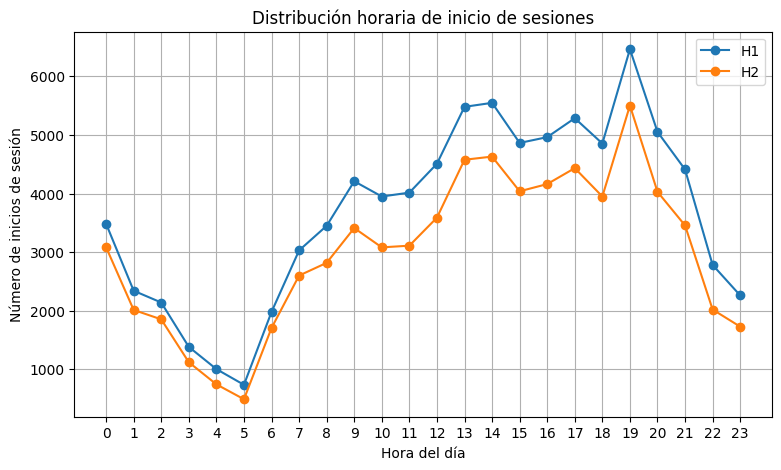

In [27]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9,5))
plt.plot(ses_30['start'].dt.hour.value_counts().sort_index(), marker='o', label='H1')
plt.plot(ses_h2['start'].dt.hour.value_counts().sort_index(), marker='o', label='H2')
plt.xlabel('Hora del día')
plt.ylabel('Número de inicios de sesión')
plt.title('Distribución horaria de inicio de sesiones')
plt.xticks(range(0, 24)) # Set x-axis ticks from 0 to 23
plt.legend()
plt.grid(True)
plt.show()

/tmp/ipython-input-3536374946.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Heuristic', y='Duration', data=df_compare, palette={'H1': 'skyblue', 'H2': 'salmon'})


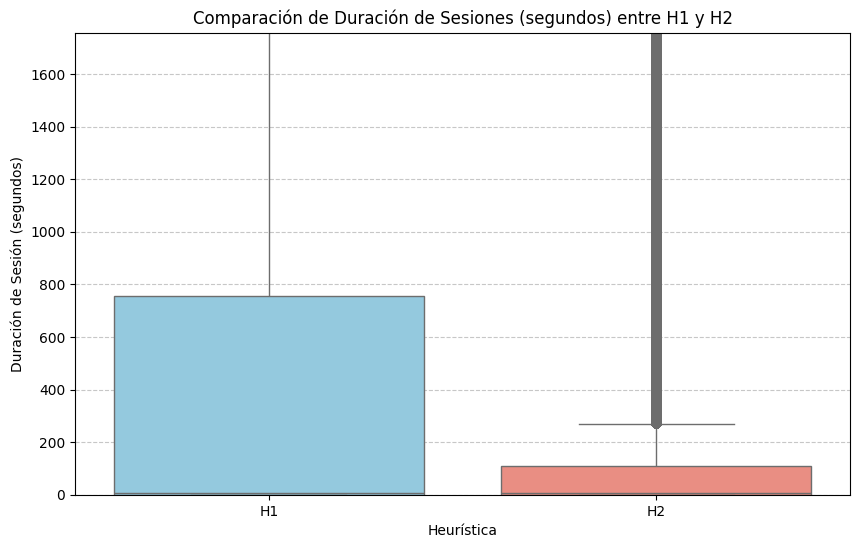

In [28]:
import seaborn as sns


# Prepare data for box plot
df_compare = pd.DataFrame({
    'Heuristic': ['H1'] * len(ses_30) + ['H2'] * len(ses_h2),
    'Duration': pd.concat([ses_30['duration_sec'], ses_h2['duration_sec']])
})

plt.figure(figsize=(10, 6))
sns.boxplot(x='Heuristic', y='Duration', data=df_compare, palette={'H1': 'skyblue', 'H2': 'salmon'})
plt.title('Comparación de Duración de Sesiones (segundos) entre H1 y H2')
plt.xlabel('Heurística')
plt.ylabel('Duración de Sesión (segundos)')
plt.ylim(0, df_compare['Duration'].quantile(0.95)) # Limit y-axis to focus on main distribution, ignoring extreme outliers
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Sistemas de Recomendación

En esta segunda parte utilizamos datos de reseñas de productos de Amazon para construir y evaluar distintos sistemas de recomendación. Se trabaja con dos categorías: **Digital Music** y **Health and Personal Care**, lo que permite comparar el comportamiento de los métodos en dominios distintos. El objetivo es predecir el rating que un usuario asignaría a un ítem a partir de su historial y el de otros usuarios, implementando desde cero modelos de filtrado colaborativo y un modelo baseline adicional, y luego comparando su desempeño con métricas cuantitativas.


In [31]:
# Subiendo y leyendo datos
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
ruta_dmusic = "/content/drive/My Drive/Digital_Music.jsonl.gz"
ruta_hpc = "/content/drive/My Drive/Health_and_Personal_Care.jsonl.gz"
dmusic= pd.read_json(ruta_dmusic, compression='gzip', lines=True)
hpc = pd.read_json(ruta_hpc, compression='gzip', lines=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
dmusic.head()


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5,Nice,If i had a dollar for how many times I have pl...,[],B004RQ2IRG,B004RQ2IRG,AFUOYIZBU3MTBOLYKOJE5Z35MBDA,2021-04-21 02:36:53.292,0,True
1,5,Excellent,awesome sound - cant wait to see them in perso...,[],B0026UZEI0,B0026UZEI0,AHGAOIZVODNHYMNCBV4DECZH42UQ,2011-06-15 19:52:05.000,0,True
2,5,Great service,This is a great cd. Good music and plays well....,[],B0055JSYHC,B0055JSYHC,AFGEM6BXCYHUILEOA3P2ZYBEF2TA,2021-03-15 20:06:33.006,0,True
3,1,No good,"These are not real German singers, they have a...",[],B000F9SMUQ,B000F9SMUQ,AH3OG6QD6EDJGZRVCFKV4B66VWNQ,2014-07-13 02:49:01.000,0,True
4,3,"Cool concept, so-so execution...",I first heard this playing in a Nagoya shop an...,[],B0049D1WVK,B0049D1WVK,AFW2PDT3AMT4X3PYQG7FJZH5FXFA,2011-06-25 19:19:55.000,0,False


In [33]:
hpc.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4,12 mg is 12 on the periodic table people! Mg f...,This review is more to clarify someone else’s ...,[],B07TDSJZMR,B07TDSJZMR,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,2020-02-06 00:49:35.902,3,True
1,5,Save the lanet using less plastic.,Love these easy multitasking bleach tablets. B...,[],B08637FWWF,B08637FWWF,AEVWAM3YWN5URJVJIZZ6XPD2MKIA,2020-11-02 22:03:06.880,3,True
2,5,Fantastic,I have been suffering a couple months with hee...,[],B07KJVGNN5,B07KJVGNN5,AHSPLDNW5OOUK2PLH7GXLACFBZNQ,2019-07-24 11:13:58.905,0,True
3,4,It holds the water and makes bubbles. That's ...,"It's cheap and it does what I wanted. The ""ma...",[],B007HY7GC2,B092RP73CX,AEZGPLOYTSAPR3DHZKKXEFPAXUAA,2022-09-04 02:29:02.725,7,True
4,1,Not for me,Didn't do a thing for me. Not saying they don'...,[],B08KYJLF5T,B08KYJLF5T,AEQAYV7RXZEBXMQIQPL6KCT2CFWQ,2022-01-20 23:53:07.262,0,True


## Selección

A partir de los archivos `Digital_Music.jsonl.gz` y `Health_and_Personal_Care.jsonl.gz` se cargan las reseñas y se seleccionan sólo las columnas necesarias para el sistema de recomendación: `user_id`, `asin` (identificador del producto) y `rating`. Esto genera dos dataframes: `dmusic_reviews` y `hpc_reviews`, que representan las interacciones usuario–producto con una calificación asociada. El resto de la información disponible en las reseñas (texto, título, etc.).


In [34]:
# Selección
dmusic_reviews = dmusic[['user_id','asin','rating']].copy()
hpc_reviews    = hpc[['user_id','asin','rating']].copy()

## Preprocesamiento y transformación

Primero se homogenizan los tipos de datos: se fuerza `user_id` y `asin` a ser cadenas de texto y se convierte `rating` a numérico, eliminando registros con valores missing. Luego se eliminan duplicados usuario–producto, manteniendo una sola reseña por par (`user_id`, `asin`).

Sobre estas bases se implementa un esquema de validación **leave-one-out por usuario**: para cada usuario se reserva una interacción para el conjunto de test y el resto queda en train. De esta forma, todos los usuarios aparecen en ambos conjuntos y se evalúa la capacidad del modelo de recuperar un ítem “oculto” del historial del usuario.

A continuación se codifican usuarios e ítems como índices enteros y se construyen matrices dispersas usuario–ítem (`R` y `R_hpc`) en formato CSR, junto con estructuras auxiliares (`user_items`, `item_users`, promedios por usuario, etc.) que se utilizan en los algoritmos de filtrado colaborativo.

Finalmente, se analiza la distribución de ratings en ambas categorías. Los gráficos de barras muestran un **desbalance muy marcado hacia la calificación 5**: la gran mayoría de reseñas son de 5 estrellas y las calificaciones bajas (1–2 estrellas) son muy poco frecuentes. Este desbalance tiene consecuencias directas en la evaluación: un modelo que se limite a predecir siempre valores cercanos a 5 puede obtener un RMSE aparentemente bueno sin “entender” realmente las diferencias entre ítems.


In [35]:
# Conversión
dmusic_reviews['user_id'] = dmusic_reviews['user_id'].astype(str)
dmusic_reviews['asin']    = dmusic_reviews['asin'].astype(str)
dmusic_reviews['rating']  = pd.to_numeric(dmusic_reviews['rating'], errors='coerce')

hpc_reviews['user_id'] = hpc_reviews['user_id'].astype(str)
hpc_reviews['asin']    = hpc_reviews['asin'].astype(str)
hpc_reviews['rating']  = pd.to_numeric(hpc_reviews['rating'], errors='coerce')

# Na
dmusic_reviews = dmusic_reviews.dropna(subset=['rating'])
hpc_reviews    = hpc_reviews.dropna(subset=['rating'])


/tmp/ipython-input-3671686441.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_counts.index, y=rating_counts.values, palette='viridis')


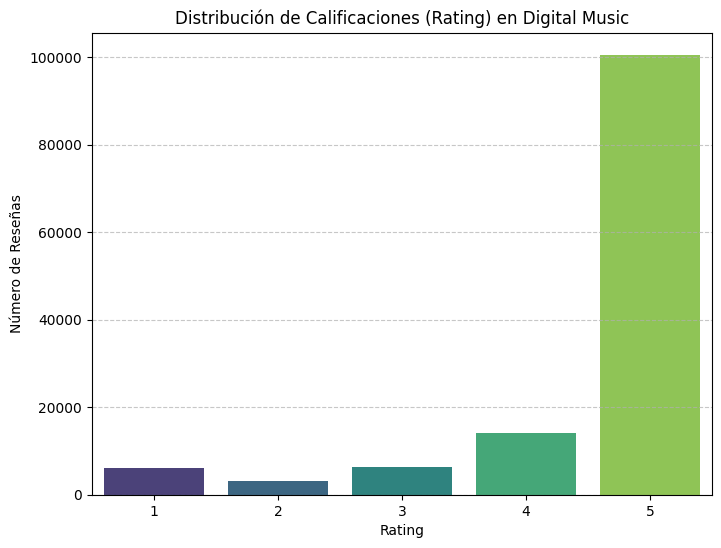

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribución de ratings en dmusic
rating_counts = dmusic_reviews['rating'].value_counts().sort_index()

plt.figure(figsize=(8, 6))
sns.barplot(x=rating_counts.index, y=rating_counts.values, palette='viridis')
plt.title('Distribución de Calificaciones (Rating) en Digital Music')
plt.xlabel('Rating')
plt.ylabel('Número de Reseñas')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipython-input-800872015.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_counts_hpc.index, y=rating_counts_hpc.values, palette='viridis')


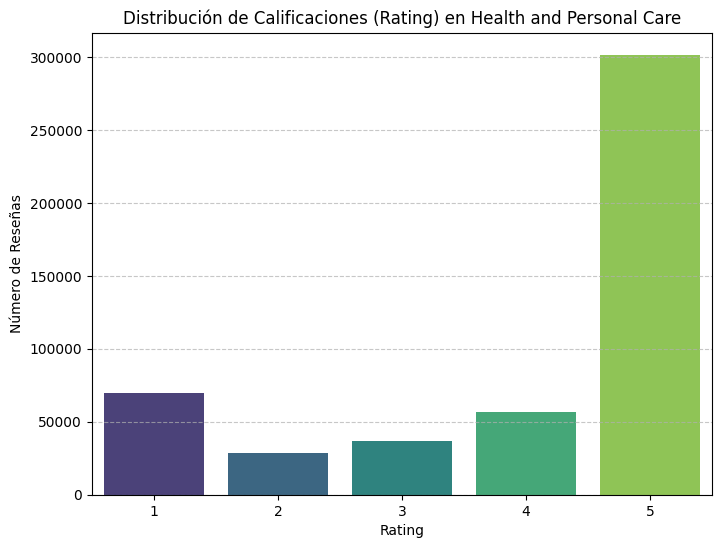

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribución de rating en hpc
rating_counts_hpc = hpc_reviews['rating'].value_counts().sort_index()

plt.figure(figsize=(8, 6))
sns.barplot(x=rating_counts_hpc.index, y=rating_counts_hpc.values, palette='viridis')
plt.title('Distribución de Calificaciones (Rating) en Health and Personal Care')
plt.xlabel('Rating')
plt.ylabel('Número de Reseñas')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Sistemas de Recomendación

Se implementan tres sistemas para cada categoría:

1. **Filtrado colaborativo basado en usuarios (User-Based CF)**.
2. **Filtrado colaborativo basado en ítems (Item-Based CF)**.
3. **Modelo baseline de promedio global de rating**.



### Sistemas para Digital Music

Para la categoría **Digital Music** se construye primero la matriz usuario–ítem `R` y las estructuras auxiliares. El **User-Based CF** calcula similitudes de Pearson entre usuarios sobre los ítems que ambos han calificado (centrando los ratings respecto al promedio del usuario). Para predecir el rating de un usuario `u` sobre un ítem `i`, se seleccionan los vecinos más similares que también calificaron `i` y se combina la desviación respecto al promedio de `u`, ponderada por la similitud; si no hay vecinos válidos, se devuelve el promedio del usuario.

El **Item-Based CF** utiliza una matriz centrada por media de usuario y una similitud de coseno ajustado entre ítems. Para predecir la calificación de `u` en el ítem `i`, se buscan ítems similares a `i` que el usuario ya haya calificado, se combinan sus desviaciones respecto al promedio de `u` y se suma esta corrección al promedio del usuario, acotando siempre el resultado al rango [1, 5].

El **modelo baseline de promedio global** para Digital Music simplemente devuelve el promedio global de los ratings del conjunto de entrenamiento, independiente de quién sea el usuario o cuál sea el ítem. Este modelo no captura personalización, pero sirve como referencia mínima para evaluar si los métodos colaborativos realmente agregan valor.



In [38]:
# Split, codificación y matriz usuario-item
###digital music
data = dmusic_reviews[['user_id','asin','rating']].copy()
data['user_id'] = data['user_id'].astype(str)
data['asin']    = data['asin'].astype(str)
data['rating']  = pd.to_numeric(data['rating'], errors='coerce')
data = data.dropna(subset=['user_id','asin','rating']).drop_duplicates(subset=['user_id','asin']).reset_index(drop=True)

# Split leave-one-out por usuario
def leave_one_out(df: pd.DataFrame):
    df = df.sort_values(['user_id','asin'])
    mask = df.groupby('user_id').cumcount(ascending=False) == 0
    test  = df[mask]
    train = df[~mask]
    valid_users = set(train['user_id']).intersection(test['user_id'])
    return (train[train['user_id'].isin(valid_users)].reset_index(drop=True),
            test [test ['user_id'].isin(valid_users)].reset_index(drop=True))

train, test = leave_one_out(data)

# Codificasion a indices
uid2idx = {u:i for i,u in enumerate(train['user_id'].unique())}
iid2idx = {i:j for j,i in enumerate(train['asin'].unique())}
idx2uid = {i:u for u,i in uid2idx.items()}
idx2iid = {j:i for i,j in iid2idx.items()}

nu, ni = len(uid2idx), len(iid2idx)
u_idx = train['user_id'].map(uid2idx).astype(int)
i_idx = train['asin'].map(iid2idx).astype(int)
r_val = train['rating'].astype(float).values

# Matriz usuario item
R = csr_matrix((r_val, (u_idx, i_idx)), shape=(nu, ni))

# Vecindarios, que calificó cada usuario y que usuarios calificaron cada item
user_items = defaultdict(set)
item_users = defaultdict(set)
for u, i in zip(u_idx, i_idx):
    user_items[u].add(i)
    item_users[i].add(u)

# Primedio por usuario
user_mean = np.zeros(nu, dtype=float)
for u in range(nu):
    items = list(user_items[u])
    user_mean[u] = R[u, items].toarray().ravel().mean() if items else 0.0

# Evaluación
def rmse(pred, true):
    pred = np.array(pred, dtype=float)
    true = np.array(true, dtype=float)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

test_u = test['user_id'].map(uid2idx)
test_i = test['asin'].map(iid2idx)
mask   = test_u.notna() & test_i.notna()
test_u = test_u[mask].astype(int).values
test_i = test_i[mask].astype(int).values
test_r = test.loc[mask, 'rating'].values

print(f"[dmusic] Usuarios: {nu} | Ítems: {ni} | Train: {train.shape} | Test: {test.shape}")


[dmusic] Usuarios: 11971 | Ítems: 22460 | Train: (27812, 3) | Test: (11971, 3)


In [39]:
# SISTEMA 1 — USER-BASED CF para dmusic

def pearson(u: int, v: int) -> float:
    # Correlación de Pearson centrada por media de usuario
    common = list(user_items[u] & user_items[v])
    if len(common) < 2:
        return 0.0

    ru = R[u, common].toarray().ravel() - user_mean[u]
    rv = R[v, common].toarray().ravel() - user_mean[v]

    num = float(np.dot(ru, rv))
    den = float(np.linalg.norm(ru) * np.linalg.norm(rv))
    return (num / den) if den > 0 else 0.0


def predict_user_based(
    u: int,
    p: int,
    K: int = 30,
    shrink: int = 10,
    sim_threshold: float = 0.0,
) -> float:
    """Predicción CF usuario-usuario para el usuario u y el ítem p."""
    neighbors = list(item_users.get(p, []))
    if not neighbors:
        return float(user_mean[u])

    sims = []
    for v in neighbors:
        if v == u:
            continue
        s = pearson(u, v)
        if s == 0.0:
            continue

        overlap = len(user_items[u] & user_items[v])
        s_adj = (overlap / (overlap + shrink)) * s  # shrinkage

        if abs(s_adj) >= sim_threshold:
            sims.append((v, s_adj))

    if not sims:
        return float(user_mean[u])

    sims.sort(key=lambda x: abs(x[1]), reverse=True)
    sims = sims[:K]

    num = den = 0.0
    for v, s in sims:
        r_vp = float(R[v, p])
        if r_vp == 0.0:
            continue
        num += s * (r_vp - user_mean[v])
        den += abs(s)

    if den == 0.0:
        pred = float(user_mean[u])
    else:
        pred = float(user_mean[u] + num / den)

    # Limitar al rango [1, 5]
    pred = max(1.0, min(5.0, pred))
    return pred


# --- Guardar predicciones y métrica para dmusic (se usarán en la sección de evaluación) ---

preds_user_dmusic = np.array([predict_user_based(u, i, K=30)
                              for u, i in zip(test_u, test_i)])
rmse_user_dmusic = rmse(preds_user_dmusic, test_r)


In [40]:
# SISTEMA 2 — ITEM-BASED CF (Digital Music)

# Matriz centrada por media de usuario (para adjusted cosine)
R_centered = R.copy().astype(float)
for u in range(R_centered.shape[0]):
    start, end = R_centered.indptr[u], R_centered.indptr[u + 1]
    R_centered.data[start:end] -= user_mean[u]


def adjusted_cosine(i: int, j: int) -> float:
    """Similitud coseno ajustado entre ítems i y j."""
    Ui = item_users.get(i, set())
    Uj = item_users.get(j, set())
    common = list(Ui & Uj)
    if len(common) < 2:
        return 0.0

    vi = R_centered[common, i].toarray().ravel()
    vj = R_centered[common, j].toarray().ravel()

    num = float(np.dot(vi, vj))
    den = float(np.linalg.norm(vi) * np.linalg.norm(vj))
    return (num / den) if den > 0 else 0.0


def predict_item_based(
    u: int,
    p: int,
    K: int = 30,
    shrink: int = 10,
    sim_threshold: float = 0.0,
) -> float:
    """Predicción CF ítem-ítem para el usuario u y el ítem p."""
    rated = list(user_items[u])
    if not rated:
        return float(user_mean[u])

    sims = []
    for i in rated:
        s = adjusted_cosine(i, p)
        if s == 0.0:
            continue

        overlap = len(item_users.get(i, set()) & item_users.get(p, set()))
        s_adj = (overlap / (overlap + shrink)) * s

        if abs(s_adj) >= sim_threshold:
            sims.append((i, s_adj))

    if not sims:
        return float(user_mean[u])

    sims.sort(key=lambda x: abs(x[1]), reverse=True)
    sims = sims[:K]

    num = den = 0.0
    for i, s in sims:
        r_ui = float(R[u, i])
        if r_ui == 0.0:
            continue
        # desvío respecto a la media del usuario (coherente con el centrado)
        num += s * (r_ui - user_mean[u])
        den += abs(s)

    if den == 0.0:
        pred = float(user_mean[u])
    else:
        pred = float(user_mean[u] + num / den)

    # Limitar al rango [1, 5]
    pred = max(1.0, min(5.0, pred))
    return pred


# --- Guardar predicciones y métrica para dmusic (se usarán en la sección de evaluación) ---

preds_item_dmusic = np.array([predict_item_based(u, i, K=30)
                              for u, i in zip(test_u, test_i)])
rmse_item_dmusic = rmse(preds_item_dmusic, test_r)


### Sistemas para Health and Personal Care

Para la categoría **Health and Personal Care (HPC)** se repite la misma lógica con una matriz `R_hpc`. El **User-Based CF** en HPC usa una versión análoga de la correlación de Pearson (`pearson_hpc`) sobre conjuntos de ítems compartidos, centrando por la media de cada usuario y combinando los ratings de los vecinos más similares para generar una predicción acotada entre 1 y 5.

El **Item-Based CF** en HPC implementa un coseno ajustado sobre una matriz centrada por media de usuario (`R_centered_hpc`). La predicción para un par usuario–ítem se obtiene promediando, con pesos de similitud, las desviaciones de los ítems vecinos y sumándolas al promedio del usuario.

Finalmente, el **modelo baseline de promedio global en HPC** devuelve para cualquier par usuario–producto el promedio global de los ratings de entrenamiento en esa categoría. Esto define una línea base que sirve para evidenciar cuánto (o cuán poco) mejoran los sistemas colaborativos sobre un punto de partida.


In [41]:
# Split, codificación y matriz usuario-ítem
data_hpc = hpc_reviews[['user_id', 'asin', 'rating']].copy()
data_hpc = (
    data_hpc
    .dropna(subset=['user_id', 'asin', 'rating'])
    .drop_duplicates(subset=['user_id', 'asin'])
    .reset_index(drop=True)
)

# Split leave-one-out por usuario
train_hpc, test_hpc = leave_one_out(data_hpc)

# Conjunto total de usuarios e ítems (train + test)
all_users_hpc = pd.Index(
    pd.concat([train_hpc['user_id'], test_hpc['user_id']]).unique()
)
all_items_hpc = pd.Index(
    pd.concat([train_hpc['asin'], test_hpc['asin']]).unique()
)
# Mapas ID  índice
uid2idx_hpc = {u: i for i, u in enumerate(all_users_hpc)}
idx2uid_hpc = {i: u for u, i in uid2idx_hpc.items()}
iid2idx_hpc = {a: j for j, a in enumerate(all_items_hpc)}
idx2iid_hpc = {j: a for a, j in iid2idx_hpc.items()}

nu_hpc, ni_hpc = len(all_users_hpc), len(all_items_hpc)

# Índices de train
train_u_hpc = train_hpc['user_id'].map(uid2idx_hpc).astype(int).to_numpy()
train_i_hpc = train_hpc['asin'].map(iid2idx_hpc).astype(int).to_numpy()
train_r_hpc = train_hpc['rating'].astype(float).to_numpy()

# Matriz usuario-ítem
R_hpc = csr_matrix((train_r_hpc, (train_u_hpc, train_i_hpc)), shape=(nu_hpc, ni_hpc))

user_items_hpc = defaultdict(set)
item_users_hpc = defaultdict(set)

for u_idx, i_idx in zip(train_u_hpc, train_i_hpc):
    user_items_hpc[u_idx].add(i_idx)
    item_users_hpc[i_idx].add(u_idx)

# Media de rating por usuario
user_mean_hpc = np.zeros(nu_hpc, dtype=float)
for u in range(nu_hpc):
    items_u = list(user_items_hpc[u])
    if items_u:
        user_mean_hpc[u] = R_hpc[u, items_u].toarray().ravel().mean()
    else:
        user_mean_hpc[u] = 0.0

# Conjunto de test mapeado a índices
test_u_hpc = test_hpc['user_id'].map(uid2idx_hpc)
test_i_hpc = test_hpc['asin'].map(iid2idx_hpc)
mask_hpc = test_u_hpc.notna() & test_i_hpc.notna()

test_u_hpc = test_u_hpc[mask_hpc].astype(int).to_numpy()
test_i_hpc = test_i_hpc[mask_hpc].astype(int).to_numpy()
test_r_hpc = test_hpc.loc[mask_hpc, 'rating'].astype(float).to_numpy()


In [42]:
# SISTEMA 1 — USER-BASED CF (Health & Personal Care)

def pearson_hpc(u: int, v: int) -> float:
    #Correlación de Pearson centrada por media de usuario
    common = list(user_items_hpc[u] & user_items_hpc[v])
    if len(common) < 2:
        return 0.0

    ru = R_hpc[u, common].toarray().ravel() - user_mean_hpc[u]
    rv = R_hpc[v, common].toarray().ravel() - user_mean_hpc[v]

    num = float(np.dot(ru, rv))
    den = float(np.linalg.norm(ru) * np.linalg.norm(rv))
    return (num / den) if den > 0 else 0.0


def predict_user_based_hpc(
    u: int,
    p: int,
    K: int = 30,
    shrink: int = 10,
    sim_threshold: float = 0.0,
) -> float:
    # Predicción CF usuario-usuario para el usuario u y el ítem p (HPC)
    neighbors = list(item_users_hpc.get(p, []))
    if not neighbors:
        return float(user_mean_hpc[u])

    sims = []
    for v in neighbors:
        if v == u:
            continue
        s = pearson_hpc(u, v)
        if s == 0.0:
            continue

        overlap = len(user_items_hpc[u] & user_items_hpc[v])
        s_adj = (overlap / (overlap + shrink)) * s  # shrinkage

        if abs(s_adj) >= sim_threshold:
            sims.append((v, s_adj))

    if not sims:
        return float(user_mean_hpc[u])

    sims.sort(key=lambda x: abs(x[1]), reverse=True)
    sims = sims[:K]

    num = den = 0.0
    for v, s in sims:
        r_vp = float(R_hpc[v, p])
        if r_vp == 0.0:
            continue
        num += s * (r_vp - user_mean_hpc[v])
        den += abs(s)

    if den == 0.0:
        pred = float(user_mean_hpc[u])
    else:
        pred = float(user_mean_hpc[u] + num / den)

    pred = max(1.0, min(5.0, pred))
    return pred


# Preds

preds_user_hpc = np.array([
    predict_user_based_hpc(u, i, K=30)
    for u, i in zip(test_u_hpc, test_i_hpc)
])
rmse_user_hpc = rmse(preds_user_hpc, test_r_hpc)


In [43]:
# SISTEMA 2 — ITEM-BASED CF (Health & Personal Care)

# Matriz centrada por media de usuario (para adjusted cosine en HPC)
R_centered_hpc = R_hpc.copy().astype(float)
for u in range(R_centered_hpc.shape[0]):
    start, end = R_centered_hpc.indptr[u], R_centered_hpc.indptr[u + 1]
    R_centered_hpc.data[start:end] -= user_mean_hpc[u]


def adjusted_cosine_hpc(i: int, j: int) -> float:
    """Similitud coseno ajustado entre ítems i y j (HPC)."""
    Ui = item_users_hpc.get(i, set())
    Uj = item_users_hpc.get(j, set())
    common = list(Ui & Uj)
    if len(common) < 2:
        return 0.0

    vi = R_centered_hpc[common, i].toarray().ravel()
    vj = R_centered_hpc[common, j].toarray().ravel()

    num = float(np.dot(vi, vj))
    den = float(np.linalg.norm(vi) * np.linalg.norm(vj))
    return (num / den) if den > 0 else 0.0


def predict_item_based_hpc(
    u: int,
    p: int,
    K: int = 30,
    shrink: int = 10,
    sim_threshold: float = 0.0,
) -> float:
    """Predicción CF ítem-ítem para el usuario u y el ítem p (HPC)."""
    rated = list(user_items_hpc[u])
    if not rated:
        return float(user_mean_hpc[u])

    sims = []
    for i in rated:
        s = adjusted_cosine_hpc(i, p)
        if s == 0.0:
            continue

        overlap = len(item_users_hpc.get(i, set()) & item_users_hpc.get(p, set()))
        s_adj = (overlap / (overlap + shrink)) * s

        if abs(s_adj) >= sim_threshold:
            sims.append((i, s_adj))

    if not sims:
        return float(user_mean_hpc[u])

    sims.sort(key=lambda x: abs(x[1]), reverse=True)
    sims = sims[:K]

    num = den = 0.0
    for i, s in sims:
        r_ui = float(R_hpc[u, i])
        if r_ui == 0.0:
            continue
        # desvío respecto a la media del usuario
        num += s * (r_ui - user_mean_hpc[u])
        den += abs(s)

    if den == 0.0:
        pred = float(user_mean_hpc[u])
    else:
        pred = float(user_mean_hpc[u] + num / den)


    pred = max(1.0, min(5.0, pred))
    return pred


# Preds

preds_item_hpc = np.array([
    predict_item_based_hpc(u, i, K=30)
    for u, i in zip(test_u_hpc, test_i_hpc)
])
rmse_item_hpc = rmse(preds_item_hpc, test_r_hpc)


### Sistema de recomendación propuesto: Promedio global

El modelo propuesto como método adicional es el **promedio global de rating**. Para cada categoría se calcula el promedio simple de las calificaciones en el conjunto de entrenamiento (`global_mean_dmusic` y `global_mean_hpc`). La función de predicción ignora por completo la identidad del usuario y del ítem y devuelve siempre ese mismo valor.




In [44]:
# SISTEMA 3 BASELINE PROMEDIO GLOBAL (Digital Music)

# Promedio global de los ratings en el conjunto de entrenamiento de dmusic
global_mean_dmusic = float(train["rating"].mean())

def predict_global_mean_dmusic(u: int, p: int) -> float:
    """
    Predictor baseline: devuelve el promedio global
    de los ratings del conjunto de entrenamiento de dmusic.
    """
    return global_mean_dmusic

# Preds
preds_global_dmusic = np.array([
    predict_global_mean_dmusic(u, i)
    for u, i in zip(test_u, test_i)
])
rmse_global_dmusic = rmse(preds_global_dmusic, test_r)


In [45]:
# SISTEMA 3 BASELINE PROMEDIO GLOBAL (HPC)

# Promedio global de los ratings en el conjunto de entrenamiento HPC
global_mean_hpc = float(train_hpc["rating"].mean())

def predict_global_mean_hpc(u: int, p: int) -> float:
    """
    Predictor baseline: devuelve el promedio global
    de los ratings del conjunto de entrenamiento HPC.
    """
    return global_mean_hpc

# Preds
preds_global_hpc = np.array([
    predict_global_mean_hpc(u, i)
    for u, i in zip(test_u_hpc, test_i_hpc)
])
rmse_global_hpc = rmse(preds_global_hpc, test_r_hpc)


### Evaluación de sistemas

La evaluación se realiza con la métrica **RMSE** sobre los conjuntos de test obtenidos por el esquema leave-one-out. Para cada categoría se calculan los RMSE de los tres sistemas (Global Mean, User-Based CF, Item-Based CF) y se resumen en una tabla.

Los resultados obtenidos son:

- **Digital Music**
  - Global Mean: RMSE ≈ 0.889
  - User-Based CF: RMSE ≈ 1.018
  - Item-Based CF: RMSE ≈ 1.018

- **Health and Personal Care**
  - Global Mean: RMSE ≈ 1.364
  - User-Based CF: RMSE ≈ 1.603
  - Item-Based CF: RMSE ≈ 1.604

En ambas categorías, el modelo de **promedio global** obtiene el menor RMSE, superando a los sistemas colaborativos. Esto está directamente relacionado con el **desbalance extremo de los ratings hacia 5 estrellas**: si casi todas las observaciones son 5, un modelo que prediga siempre algo muy cercano a 5 reduce mucho el error cuadrático medio. En otras palabras, un modelo que siempre prediga “5 estrellas” ya es muy difícil de superar en términos de RMSE, aunque no aprovecha ninguna información sobre usuarios o ítems.

Este resultado muestra que, con datos desbalanceados, la métrica RMSE por sí sola puede ser engañosa: un modelo puede tener un RMSE bajo simplemente por ajustarse al valor mayoritario, sin capturar preferencias individuales ni recomendaciones diferenciadas.




In [46]:
# Tabla comparativa de RMSE
df_eval = pd.DataFrame({
    "Sistema": ["Global Mean", "User-Based CF", "Item-Based CF"],
    "RMSE (dmusic)": [
        rmse_global_dmusic,
        rmse_user_dmusic,
        rmse_item_dmusic
    ],
    "RMSE (HPC)": [
        rmse_global_hpc,
        rmse_user_hpc,
        rmse_item_hpc
    ]
})

df_eval


,Sistema,RMSE (dmusic),RMSE (HPC)
0,Global Mean,0.888660,1.363877
1,User-Based CF,1.018468,1.603127
2,Item-Based CF,1.018234,1.603788


In [47]:
# Predicciones vs estimaciones
print("=== Ejemplos de predicciones (dmusic) ===")
rng = np.random.default_rng(0)
idxs = rng.choice(len(test_u), size=5, replace=False)

for idx in idxs:
    u = test_u[idx]
    i = test_i[idx]
    real = test_r[idx]

    pred_user  = predict_user_based(u, i)
    pred_item  = predict_item_based(u, i)
    pred_glob  = predict_global_mean_dmusic(u, i)

    print(f"User={idx2uid[u]}, Item={idx2iid[i]}")
    print(f"   Rating Real: {real}")
    print(f"   User-Based:  {pred_user:.2f}")
    print(f"   Item-Based:  {pred_item:.2f}")
    print(f"   GlobalMean:  {pred_glob:.2f}")


=== Ejemplos de predicciones (dmusic) ===
User=AGLFQMONMYD3G2SEPTEGV6GKU7JQ, Item=B0771J5R5H
   Rating Real: 5
   User-Based:  3.00
   Item-Based:  3.00
   GlobalMean:  4.55
User=AG3GG3ABEYB2L3B5TNLRJHMAOWYA, Item=B00H4B565C
   Rating Real: 5
   User-Based:  4.67
   Item-Based:  4.67
   GlobalMean:  4.55
User=AF3PWYSKLGWCZYHAERZMSHMLCC2A, Item=B075R3HWRD
   Rating Real: 5
   User-Based:  5.00
   Item-Based:  5.00
   GlobalMean:  4.55
User=AFAUPIICERKOGGIL6DDJEE7CHXYA, Item=B08JY2Z16J
   Rating Real: 2
   User-Based:  5.00
   Item-Based:  5.00
   GlobalMean:  4.55
User=AHG5LPR65V7ZC5CCBYFJ4KFQP5OQ, Item=B004CULQDO
   Rating Real: 3
   User-Based:  4.00
   Item-Based:  4.00
   GlobalMean:  4.55


In [48]:
# Ejemplos para los 3 sistemas en hpc
print("\n=== Ejemplos de predicciones (HPC) ===")
rng = np.random.default_rng(1)
idxs = rng.choice(len(test_u_hpc), size=5, replace=False)

for idx in idxs:
    u = test_u_hpc[idx]
    i = test_i_hpc[idx]
    real = test_r_hpc[idx]

    pred_user  = predict_user_based_hpc(u, i)
    pred_item  = predict_item_based_hpc(u, i)
    pred_glob  = predict_global_mean_hpc(u, i)

    print(f"User={idx2uid_hpc[u]}, Item={idx2iid_hpc[i]}")
    print(f"   Rating Real: {real}")
    print(f"   User-Based:  {pred_user:.2f}")
    print(f"   Item-Based:  {pred_item:.2f}")
    print(f"   GlobalMean:  {pred_glob:.2f}")



=== Ejemplos de predicciones (HPC) ===
User=AG4ASK7U6EZFUPEX47KV4ODW234Q, Item=B000MSVXY2
   Rating Real: 1.0
   User-Based:  1.00
   Item-Based:  1.00
   GlobalMean:  4.22
User=AE6MHNI5UZ5DUR6TGCOLA52NORFA, Item=B00H8S0FB6
   Rating Real: 4.0
   User-Based:  3.00
   Item-Based:  3.00
   GlobalMean:  4.22
User=AH2HCSCLYKVJSOL6HMTDQGGZELPQ, Item=B00HHXFQSY
   Rating Real: 5.0
   User-Based:  5.00
   Item-Based:  5.00
   GlobalMean:  4.22
User=AHTRAUMX77EFUSVXIIKB2O3JHTTA, Item=B086HDPVNG
   Rating Real: 3.0
   User-Based:  5.00
   Item-Based:  5.00
   GlobalMean:  4.22
User=AFXATF22YP43GCQINBEOIY6DFYMQ, Item=B01M0WLGPS
   Rating Real: 5.0
   User-Based:  5.00
   Item-Based:  5.00
   GlobalMean:  4.22


# Conclusiones
En la **Parte 1**, la reconstrucción de sesiones a partir del log EClog mostró que la mayoría de las interacciones corresponden a sesiones muy cortas, con pocos hits y alta tasa de rebotes. La comparación entre las heurísticas H1 (sólo timeout de 30 minutos) y H2 (timeout + cambio de IP/UserAgent) evidenció que pequeñas diferencias en la definición de sesión afectan significativamente el número de sesiones, sus duraciones y el reparto por usuario. También se observaron patrones claros en la distribución por sistema operativo y en los horarios de mayor actividad. Esto confirma que la forma en que definimos usuarios y sesiones condiciona fuertemente cualquier análisis posterior de Web Usage Mining.

En la **Parte 2**, se construyeron sistemas de recomendación colaborativos basados en usuarios y en ítems para las categorías Digital Music y Health and Personal Care, junto con un modelo baseline de promedio global. El análisis de las distribuciones de rating mostró un **desbalance muy fuerte hacia las 5 estrellas**, lo que se reflejó directamente en la evaluación: el modelo de promedio global, que ignora por completo usuarios e ítems, obtuvo el mejor RMSE en ambas categorías.

Este resultado deja claro que, con datos tan desbalanceados, un modelo que prácticamente “predice siempre 5 estrellas” puede lograr un RMSE muy bajo sin ser realmente inteligente ni útil desde el punto de vista de personalización. Para avanzar hacia recomendaciones de mayor calidad sería necesario complementar el RMSE con otras métricas y estrategias (por ejemplo balancear mejor el conjunto de datos o incorporar información de contenido), de modo que los modelos colaborativos tengan incentivos reales para diferenciar entre productos y capturar preferencias individuales.
